# 4. Test on a New Season: 2026

The real-world test: predict the **2025–26 season**, which the model has never seen.

1. Scrape the three 2026 pages
2. Clean them exactly like `02_data_cleaning.ipynb`
3. Build the same features as `03_machine_learning.ipynb`
4. Load the saved model (`mvp_model.joblib`, trained on 1991–2025) and predict
5. Compare with the real MVP voting

The model is **not changed** in this notebook.

## Setup

In [1]:
import os
import time
import joblib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from bs4 import BeautifulSoup
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, ConfusionMatrixDisplay

YEAR = 2026
FOLDER = "data_2026"
os.makedirs(FOLDER, exist_ok=True)

## 1. Scrape

Same rules as before: save raw HTML, skip files that already exist, wait between requests.

In [2]:
def download(url, path):
    if os.path.exists(path):
        return
    page = requests.get(url)
    if page.status_code == 429:
        raise RuntimeError("Rate limited (HTTP 429). Wait 1 hour before trying again.")
    page.raise_for_status()
    with open(path, "wb") as f:
        f.write(page.content)
    print("Saved", path)
    time.sleep(7)


def read_table(path, table_id, remove_row_class=None):
    with open(path, encoding="utf-8") as f:
        soup = BeautifulSoup(f.read(), "html.parser")
    if remove_row_class:
        extra_header = soup.find("tr", class_=remove_row_class)
        if extra_header:
            extra_header.decompose()
    return pd.read_html(StringIO(str(soup.find(id=table_id))))[0]


download(f"https://www.basketball-reference.com/awards/awards_{YEAR}.html", f"{FOLDER}/mvp_{YEAR}.html")
download(f"https://www.basketball-reference.com/leagues/NBA_{YEAR}_per_game.html", f"{FOLDER}/players_{YEAR}.html")
download(f"https://www.basketball-reference.com/leagues/NBA_{YEAR}_standings.html", f"{FOLDER}/teams_{YEAR}.html")

## 2. Parse

In [3]:
mvps = read_table(f"{FOLDER}/mvp_{YEAR}.html", "mvp", remove_row_class="over_header")
mvps["Year"] = YEAR
mvps = mvps[["Player", "Year", "Pts Won", "Pts Max", "Share"]]
mvps

,Player,Year,Pts Won,Pts Max,Share
0,Shai Gilgeous-Alexander,2026,939,1000,0.939
1,Nikola Jokić,2026,634,1000,0.634
2,Victor Wembanyama,2026,569,1000,0.569
3,Luka Dončić,2026,250,1000,0.250
4,Cade Cunningham,2026,117,1000,0.117
5,Jaylen Brown,2026,89,1000,0.089
6,Kawhi Leonard,2026,1,1000,0.001
7,Donovan Mitchell,2026,1,1000,0.001


In [4]:
players = read_table(f"{FOLDER}/players_{YEAR}.html", "per_game_stats", remove_row_class="thead")
players["Year"] = YEAR

dfs = []
for table_id, conference in [("divs_standings_E", "Eastern Conference"), ("divs_standings_W", "Western Conference")]:
    team = read_table(f"{FOLDER}/teams_{YEAR}.html", table_id, remove_row_class="thead")
    dfs.append(team.rename(columns={conference: "Team"}))
teams = pd.concat(dfs, ignore_index=True)
teams["Year"] = YEAR

print("Players:", players.shape, " Teams:", teams.shape)

Players: (734, 32)  Teams: (35, 9)


## 3. Clean (same rules as `02_data_cleaning.ipynb`)

Note: the raw player table has an `Awards` column with values like `MVP-1`. That is the answer, so it is dropped.

In [5]:
players = players.drop(columns=["Rk", "Awards"])
players = players[players["Player"] != "Player"]          # repeated header rows, if any
players["Player"] = players["Player"].str.replace("*", "", regex=False)
players = players[players["Player"] != "League Average"]

# Traded players: keep the season-total row (2TM, 3TM...), labeled with the last team
group = players.groupby(["Player", "Year"])["Team"]
is_single_team = group.transform("size") == 1
is_season_total = players["Team"].str.endswith("TM")
players["Team"] = players["Team"].where(is_single_team, group.transform("last"))
players = players[is_single_team | is_season_total]

print("Duplicate players:", players["Player"].duplicated().sum())

Duplicate players: 0


In [6]:
combined = players.merge(mvps, on=["Player", "Year"], how="left")
combined[["Pts Won", "Pts Max", "Share"]] = combined[["Pts Won", "Pts Max", "Share"]].fillna(0)
print("Unmatched MVP names:", set(mvps["Player"]) - set(combined["Player"]))

nicknames = pd.read_csv("nicknames.txt").set_index("Abbreviation")["Name"].to_dict()
combined["Team"] = combined["Team"].map(nicknames)
print("Unmapped teams:", combined["Team"].isnull().sum())

teams = teams[~teams["W"].astype(str).str.contains("Division")].copy()
teams["Team"] = teams["Team"].str.replace("*", "", regex=False)
teams["GB"] = teams["GB"].astype(str).str.replace("—", "0")

stats_2026 = combined.merge(teams, on=["Team", "Year"], how="left")
print("Players without team stats:", stats_2026["W"].isnull().sum())

text_columns = ["Player", "Team", "Pos"]
numeric_columns = [c for c in stats_2026.columns if c not in text_columns]
stats_2026[numeric_columns] = stats_2026[numeric_columns].apply(pd.to_numeric)
stats_2026 = stats_2026.fillna(0)    # shooting % with 0 attempts
stats_2026.shape

Unmatched MVP names: set()
Unmapped teams: 0
Players without team stats: 0


(582, 40)

## 4. Features (same as `03_machine_learning.ipynb`)

In [7]:
for col in ["PTS", "AST", "TRB", "STL", "BLK", "W/L%", "MP", "FG%"]:
    stats_2026[f"{col}_R"] = stats_2026[col] / stats_2026[col].mean()    # one season, so the plain mean is the season average

## 5. Load the saved model and predict

In [8]:
saved = joblib.load("mvp_model.joblib")
model = saved["model"]
predictors = saved["predictors"]
print("Missing features:", set(predictors) - set(stats_2026.columns))

test = stats_2026.copy()
test["Predicted"] = model.predict(test[predictors])
test["Predicted rank"] = test["Predicted"].rank(ascending=False, method="first").astype(int)
test["Actual rank"] = test["Share"].rank(ascending=False, method="first").astype(int)

Missing features: set()


## 6. Results: actual vs predicted

In [9]:
(test.sort_values("Predicted", ascending=False)
     [["Player", "Team", "G", "PTS", "Predicted", "Share", "Predicted rank", "Actual rank"]]
     .rename(columns={"Share": "Actual"})
     .head(10).round(3).reset_index(drop=True))

,Player,Team,G,PTS,Predicted,Actual,Predicted rank,Actual rank
0,Shai Gilgeous-Alexander,Oklahoma City Thunder,68.0,31.1,0.757,0.939,1,1
1,Luka Dončić,Los Angeles Lakers,64.0,33.5,0.550,0.250,2,4
2,Nikola Jokić,Denver Nuggets,65.0,27.7,0.532,0.634,3,2
3,Jaylen Brown,Boston Celtics,71.0,28.7,0.393,0.089,4,6
4,Victor Wembanyama,San Antonio Spurs,64.0,25.0,0.215,0.569,5,3
5,Cade Cunningham,Detroit Pistons,64.0,23.9,0.215,0.117,6,5
6,Donovan Mitchell,Cleveland Cavaliers,70.0,27.9,0.131,0.001,7,8
7,Giannis Antetokounmpo,Milwaukee Bucks,36.0,27.6,0.094,0.000,8,11
8,Anthony Edwards,Minnesota Timberwolves,61.0,28.8,0.035,0.000,9,9
9,Stephon Castle,San Antonio Spurs,68.0,16.7,0.034,0.000,10,79


In [10]:
mse = mean_squared_error(test["Share"], test["Predicted"])

predicted_mvp = test.loc[test["Predicted rank"] == 1, "Player"].iloc[0]
actual_mvp = test.loc[test["Actual rank"] == 1, "Player"].iloc[0]
top5_hits = len(set(test.loc[test["Predicted rank"] <= 5, "Player"]) &
                set(test.loc[test["Actual rank"] <= 5, "Player"]))

pd.Series({
    "MSE (loss)": round(mse, 5),
    "RMSE": round(np.sqrt(mse), 4),
    "MAE": round(mean_absolute_error(test["Share"], test["Predicted"]), 4),
    "R²": round(r2_score(test["Share"], test["Predicted"]), 3),
    "Predicted MVP": predicted_mvp,
    "Actual MVP": actual_mvp,
    "MVP correct": predicted_mvp == actual_mvp,
    "Top-5 accuracy": f"{top5_hits}/5 ({top5_hits / 5:.0%})",
}, name="2026 test").to_frame()

,2026 test
MSE (loss),0.00073
RMSE,0.027
MAE,0.0045
R²,0.748
Predicted MVP,Shai Gilgeous-Alexander
Actual MVP,Shai Gilgeous-Alexander
MVP correct,True
Top-5 accuracy,4/5 (80%)


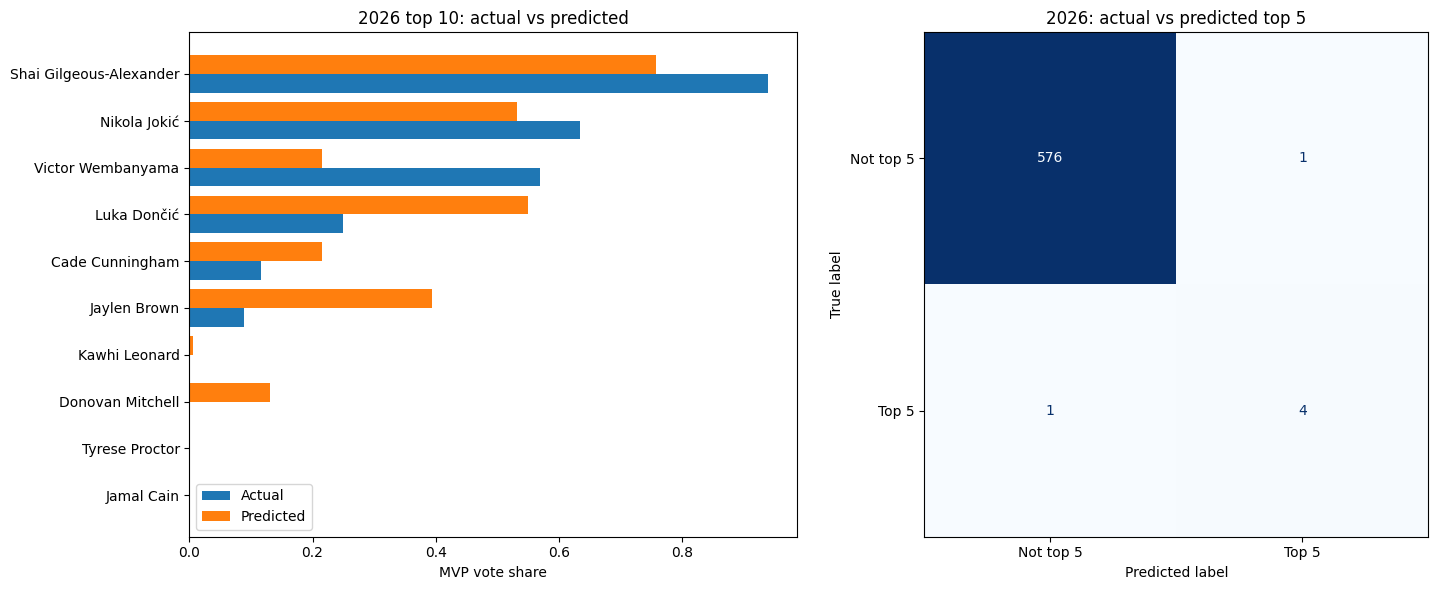

In [11]:
top = test.sort_values("Share", ascending=False).head(10).iloc[::-1]
y = np.arange(len(top))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(y - 0.2, top["Share"], height=0.4, label="Actual")
axes[0].barh(y + 0.2, top["Predicted"], height=0.4, label="Predicted")
axes[0].set_yticks(y)
axes[0].set_yticklabels(top["Player"])
axes[0].set_xlabel("MVP vote share")
axes[0].set_title("2026 top 10: actual vs predicted")
axes[0].legend()

cm = confusion_matrix(test["Actual rank"] <= 5, test["Predicted rank"] <= 5)
ConfusionMatrixDisplay(cm, display_labels=["Not top 5", "Top 5"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("2026: actual vs predicted top 5")

plt.tight_layout()
plt.show()

## Findings

- **MVP correct:** Shai Gilgeous-Alexander, predicted with a clear lead.
- **Top 5: 4 of 5 found.** Jaylen Brown is a false alarm (predicted 4th, actual 6th).
- **Near-ties:** Nikola Jokić (actual 2nd) and Luka Dončić (actual 4th) get almost the same predicted share, and so do
  Victor Wembanyama (actual 3rd) and Cade Cunningham (actual 5th). Their exact order can flip with the random seed or library version,
  but across 10 seeds the MVP pick and the 4/5 top-5 score never changed.
- **Biggest error: Wembanyama.** Predicted share ~0.21 vs actual 0.57. His value is largely defensive (rim protection),
  which basic box-score stats don't capture.

This matches the backtest: the model reliably finds the top contenders, and underrates players whose case rests on defense or advanced metrics.
**Next improvement:** add advanced stats (Win Shares, BPM, Defensive Win Shares).